In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("laptop_price_dataset.csv")

print("First 5 rows:")
print(df.head())
print("\nDataset information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

First 5 rows:
    Brand  RAM_GB  SSD_GB  Processor_Gen  Processor_Speed_GHz  Graphics_GB  \
0      HP       8    1024             14                  1.9            2   
1    Asus       8     128              8                  4.6            4   
2    Asus      16     512              8                  4.1            6   
3  Lenovo      16     512             14                  2.4            4   
4  Lenovo      16     256             12                  2.1            8   

   Price_INR  
0      69900  
1      56700  
2      62400  
3      66500  
4      67100  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Brand                150 non-null    object 
 1   RAM_GB               150 non-null    int64  
 2   SSD_GB               150 non-null    int64  
 3   Processor_Gen        150 non-null    int64  
 

In [4]:
X = df.drop("Price_INR", axis=1)
y = df["Price_INR"]


In [5]:
categorical_features = ["Brand"]
numerical_features = [
    "RAM_GB",
    "SSD_GB",
    "Processor_Gen",
    "Processor_Speed_GHz",
    "Graphics_GB"
]

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("brand", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numbers", "passthrough", numerical_features)
    ]
)

In [7]:
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [11]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('brand',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand']),
                                                 ('numbers', 'passthrough',
                                                  ['RAM_GB', 'SSD_GB',
                                                   'Processor_Gen',
                                                   'Processor_Speed_GHz',
                                                   'Graphics_GB'])])),
                ('regression', LinearRegression())])

In [13]:
y_pred = model.predict(X_test)

In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R2 Score:", round(r2, 4))


Model Evaluation:
MAE  : 4458.47
MSE  : 28374924.1
RMSE : 5326.81
R2 Score: 0.8767


In [15]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": np.round(y_pred, 2)
})
print("\nActual vs Predicted:")
print(comparison.head(10))


Actual vs Predicted:
   Actual Price  Predicted Price
0         65700         63984.44
1         37500         44720.72
2         75800         68130.11
3         74800         71778.82
4        101800         96556.56
5         60400         61845.38
6         44600         46765.11
7         51000         59153.63
8         51300         58506.78
9         64600         64612.92


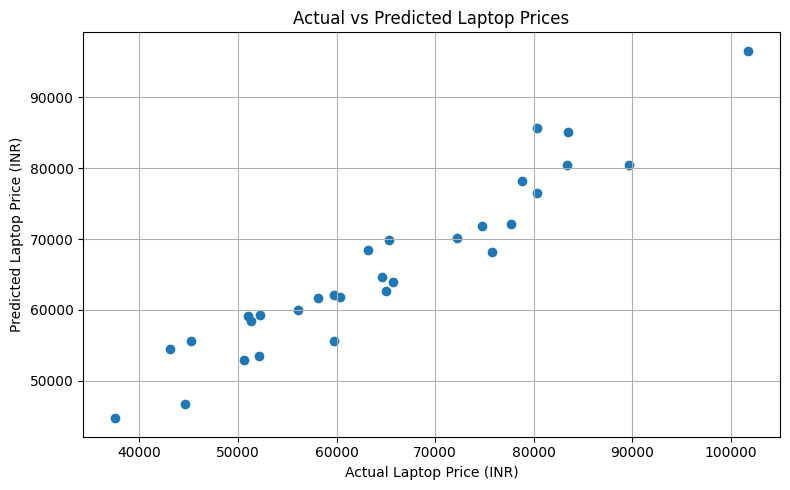

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Laptop Price (INR)")
plt.ylabel("Predicted Laptop Price (INR)")
plt.title("Actual vs Predicted Laptop Prices")
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
new_laptop = pd.DataFrame([{
    "Brand": "HP",
    "RAM_GB": 16,
    "SSD_GB": 512,
    "Processor_Gen": 12,
    "Processor_Speed_GHz": 3.5,
    "Graphics_GB": 2
}])

predicted_price = model.predict(new_laptop)[0]
print("\nNew Laptop Details:")
print(new_laptop)
print("Estimated Laptop Price: ₹", round(predicted_price, 2))


New Laptop Details:
  Brand  RAM_GB  SSD_GB  Processor_Gen  Processor_Speed_GHz  Graphics_GB
0    HP      16     512             12                  3.5            2
Estimated Laptop Price: ₹ 70490.62
